#### 사전에 구현된 모델
#### ImageNet-1k
: 딥러닝 모델의 이미지 분류 학습에 사용되는 대규모 이미지 데이터 셋<br>
강아지, 고양이, 자동차, 새, 비행기, 과일 등의 1천개의 이미지 class가 존재.

- Class : 1000
- Instance : Near 1.28 Mil
- Image_Size : non-uniform


In [1]:
# Summary 기능을 이용을 위한 Torchinfo Download
# %pip install torchinfo

In [2]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torchvision import models, transforms, datasets
from torchinfo import summary
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
weights = models.ResNet50_Weights.IMAGENET1K_V2
load_model = models.resnet50(weights=weights)
print(load_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [4]:
load_model.eval()
with torch.no_grad():
    print(load_model(torch.randn(2,3,224,224)).shape)
    # 결과 클래스 출력 원하면 softmax -> argmax

torch.Size([2, 1000])


In [5]:
# 모델 전체 구조, 각 층의 출력 크기, 파라미터 개수, 연산량 등을 확인하는 함수
summary(load_model, input_size=(2,3,224,224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [2, 1000]                 --
├─Conv2d: 1-1                            [2, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [2, 64, 112, 112]         128
├─ReLU: 1-3                              [2, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [2, 64, 56, 56]           --
├─Sequential: 1-5                        [2, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [2, 256, 56, 56]          --
│    │    └─Conv2d: 3-1                  [2, 64, 56, 56]           4,096
│    │    └─BatchNorm2d: 3-2             [2, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [2, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [2, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [2, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [2, 64, 56, 56]           --
│ 

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(size=(256)),  # size 는 값 하나만 입력해도 짧은 쪽을 기준으로 resize 수행
    transforms.CenterCrop(size=(224,224))
])

In [7]:
# 모델의 weights key값 확인
# meta는 사전학습된 가중치에 대한 부가정보를 딕셔너리 형태로 저장
print(weights.meta.keys())
# recipe : 모델 학습 방법
# metics : 모델 성능
# ops : 연산량
# file_size : 모델 가중치 파일의 크기
# docs : 가중치에 대한 설명

dict_keys(['min_size', 'categories', 'num_params', 'recipe', '_metrics', '_ops', '_file_size', '_docs'])


In [8]:
# 모델의 class의 인덱스를 변수에 넣고 저장
idx2label = dict(enumerate(weights.meta['categories']))
print(idx2label)
print(idx2label[25])

{0: 'tench', 1: 'goldfish', 2: 'great white shark', 3: 'tiger shark', 4: 'hammerhead', 5: 'electric ray', 6: 'stingray', 7: 'cock', 8: 'hen', 9: 'ostrich', 10: 'brambling', 11: 'goldfinch', 12: 'house finch', 13: 'junco', 14: 'indigo bunting', 15: 'robin', 16: 'bulbul', 17: 'jay', 18: 'magpie', 19: 'chickadee', 20: 'water ouzel', 21: 'kite', 22: 'bald eagle', 23: 'vulture', 24: 'great grey owl', 25: 'European fire salamander', 26: 'common newt', 27: 'eft', 28: 'spotted salamander', 29: 'axolotl', 30: 'bullfrog', 31: 'tree frog', 32: 'tailed frog', 33: 'loggerhead', 34: 'leatherback turtle', 35: 'mud turtle', 36: 'terrapin', 37: 'box turtle', 38: 'banded gecko', 39: 'common iguana', 40: 'American chameleon', 41: 'whiptail', 42: 'agama', 43: 'frilled lizard', 44: 'alligator lizard', 45: 'Gila monster', 46: 'green lizard', 47: 'African chameleon', 48: 'Komodo dragon', 49: 'African crocodile', 50: 'American alligator', 51: 'triceratops', 52: 'thunder snake', 53: 'ringneck snake', 54: 'hogn

In [9]:
# 이미지 데이터 읽고 쓰기용 크로스플랫폼 파이썬 라이브러리
# %pip install imageio

(708, 1071, 3)
<class 'numpy.ndarray'>


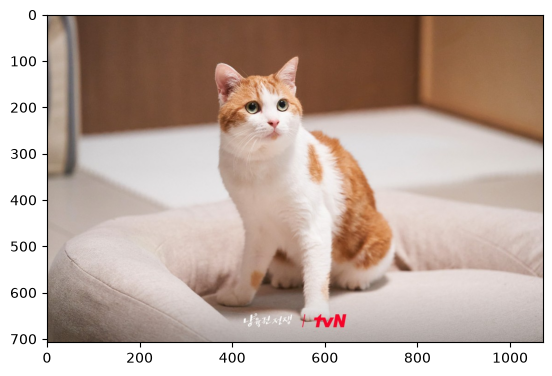

In [10]:
import imageio.v2 as imageio

X = imageio.imread(
        'https://cdn.news.koreanbar.or.kr/news/photo/202509/34214_26713_5731.jpg'
                  )

print(X.shape)
print(type(X))
plt.imshow(X)

torch.Size([3, 224, 224])
<class 'torch.Tensor'>
torch.Size([1, 3, 224, 224])


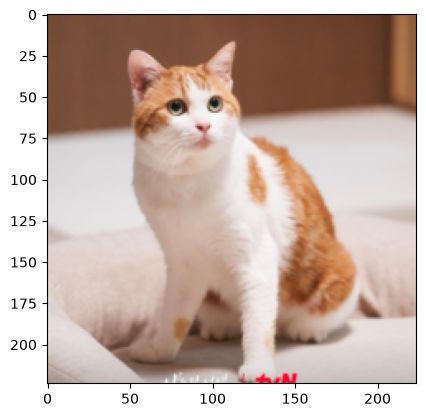

In [11]:
X = transform(X)
print(X.shape)
print(type(X))

plt.imshow(X.permute(1,2,0))

X = X.unsqueeze(dim=0)  # 차원 추가
print(X.shape)

In [15]:
load_model.eval()
with torch.no_grad():
    y_hat_sorted = load_model(X).sort(descending=True) # 예측값 중 가장 큰 값이 가장 위에 위치하도록
    percent_top5 = F.softmax(y_hat_sorted[0], dim=1)[0,:5]*100  # 상위 5개의 확률값
    print(percent_top5)

    pred_top5 = y_hat_sorted[1][0,:5]   # [0]: 점수 , [1]: class idx
    print(pred_top5)

for i, idx in enumerate(pred_top5):
    print(f'{idx2label[idx.item()]} ({round(percent_top5[i].item(), 1)}%)')

tensor([19.0127, 13.7699,  5.6202,  3.4820,  2.5831])
tensor([285, 282, 876, 281, 435])
Egyptian cat (19.0%)
tiger cat (13.8%)
tub (5.6%)
tabby (3.5%)
bathtub (2.6%)


Text(0.5, 1.0, 'Egyptian cat (19.0%)')

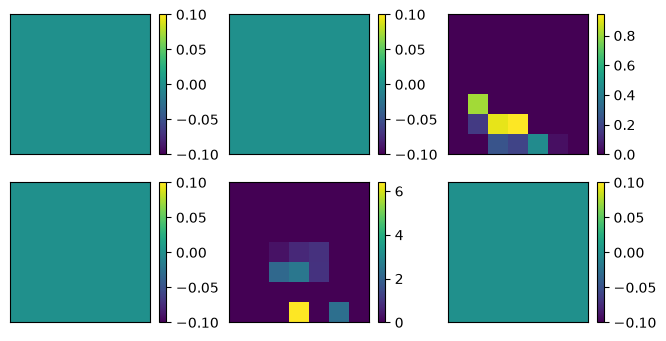

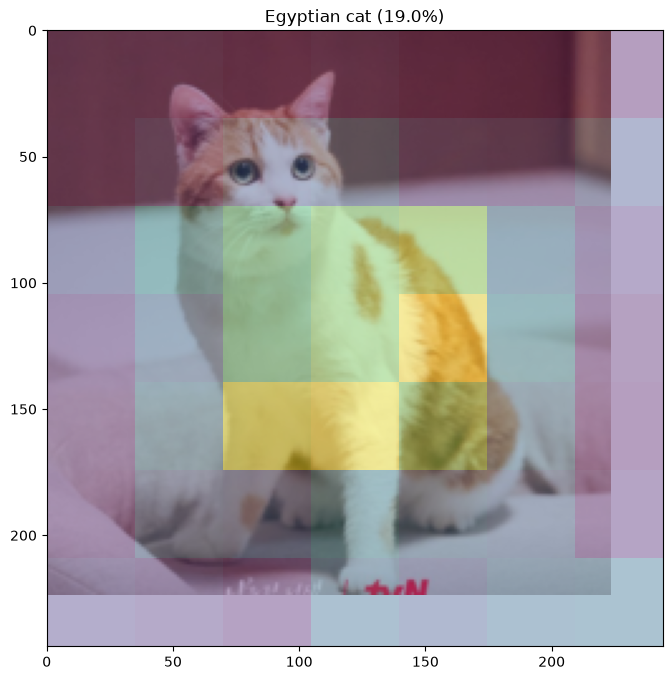

In [16]:
# feature map transfer
load_model.eval()
features = nn.Sequential(*list(load_model.children())[:-2])   
# layer의 내용을 가져와서 list로 출력, avgpool2d & linear 제외
# list를 unpacking 하여 새로운 Sequential 신경망으로 저장

with torch.no_grad():
    X_features = features(X)

plt.figure(figsize=(8,4))
for i in range(6):
    plt.subplot(2,3, i+1, xticks=[], yticks=[])
    plt.imshow(X_features[0,i])
    plt.colorbar()

summed_map = X_features.sum(dim=1)   # 행방향 합

plt.figure(figsize=(8,8))
plt.xticks=[]
plt.yticks=[]
plt.imshow(X[0].permute(1,2,0))
plt.imshow(summed_map[0], extent=[0,244,244,0], alpha=0.4)

pred_class = idx2label[pred_top5[0].item()]
plt.title(f'{pred_class} ({round(percent_top5[0].item(),1)}%)')